# Stage 1: dataset description, EDA, and feature extraction

Fire, smoke, and neutral scene classification for the MIDS w281 final project.

This notebook is written to run from top to bottom in Google Colab. The first code cell installs the packages Colab does not already provide, then the notebook downloads the dataset, describes it, and extracts three feature families:

1. A simple feature: an HSV color histogram.
2. A hand-designed feature: geometry of a flame-colored region.
3. A pretrained feature: a 2048-dimensional ResNet50 embedding.

It then plots how those features vary across the three classes, and it reduces them with PCA and t-SNE.

Stage 1 output categories are Fire, Smoke, and Neutral. The later grid-level intensity task is out of scope here.

Turn on a GPU runtime if you have one (Runtime, Change runtime type, T4 GPU). The notebook still runs on CPU. Set `QUICK = True` in the setup cell if you only want a short check.


## 0. Install and import

Colab already has PyTorch. The install cell adds OpenCV, scikit-learn, and the plotting libraries used below.


In [1]:
# Colab install. Safe to rerun locally; packages that are already present are left alone.
%pip install -q opencv-python-headless scikit-learn matplotlib pandas tqdm pillow


In [2]:
import sys
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from PIL import Image
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
from torchvision.models import ResNet50_Weights, resnet50
from tqdm.auto import tqdm

IN_COLAB = "google.colab" in sys.modules

# Full training set by default. Set True for a fast sanity check (40 images per class).
QUICK = False
SAMPLE_PER_CLASS = 40
RANDOM_STATE = 0
IMAGE_SIZE = 224

CLASSES = ["Fire", "Smoke", "Neutral"]
CLASS_COLORS = {"Fire": "#d35400", "Smoke": "#7f8c8d", "Neutral": "#1e8449"}

if IN_COLAB:
    ROOT = Path("/content/MIDS-281-project")
else:
    ROOT = Path.cwd()
    if ROOT.name == "notebooks":
        ROOT = ROOT.parent

DATA_DIR = ROOT / "data"
DATASET_DIR = DATA_DIR / "FIRE-SMOKE-DATASET"
OUTPUT_DIR = ROOT / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Colab:", IN_COLAB)
print("Project root:", ROOT)
print("Torch:", torch.__version__, "| CUDA:", torch.cuda.is_available())


Colab: True
Project root: /content/MIDS-281-project
Torch: 2.11.0+cpu | CUDA: False


## 1. Dataset

**Link:** [DeepQuestAI Fire-Smoke-Dataset v1](https://github.com/DeepQuestAI/Fire-Smoke-Dataset/releases/download/v1/FIRE-SMOKE-DATASET.zip)

The zip is the same release used in `00_extract_dataset.ipynb`. It is organized as `Train/` and `Test/`, and each split has three folders: `Fire`, `Smoke`, and `Neutral`.

The proposal expects about 1,000 images in each category, roughly 900 for training and 100 for testing. The next cells download the zip if it is not already under `data/`, then count the files so the report uses the actual inventory rather than the proposal's round numbers.


In [3]:
import urllib.request
import zipfile

DATASET_URL = (
    "https://github.com/DeepQuestAI/Fire-Smoke-Dataset/"
    "releases/download/v1/FIRE-SMOKE-DATASET.zip"
)
ZIP_PATH = DATA_DIR / "FIRE-SMOKE-DATASET.zip"
DATA_DIR.mkdir(parents=True, exist_ok=True)

if not DATASET_DIR.exists():
    if not ZIP_PATH.exists():
        print("Downloading dataset...")
        urllib.request.urlretrieve(DATASET_URL, ZIP_PATH)
    print("Unzipping...")
    with zipfile.ZipFile(ZIP_PATH) as zf:
        zf.extractall(DATA_DIR)
else:
    print("Dataset already present:", DATASET_DIR)

assert (DATASET_DIR / "Train").exists(), DATASET_DIR
assert (DATASET_DIR / "Test").exists(), DATASET_DIR
print("Ready:", DATASET_DIR)


Unzipping...
Ready: /content/MIDS-281-project/data/FIRE-SMOKE-DATASET


In [4]:
EXTENSIONS = {".jpg", ".jpeg", ".png"}

def list_images(split):
    records = []
    for label in CLASSES:
        folder = DATASET_DIR / split / label
        paths = sorted(
            p for p in folder.rglob("*")
            if p.is_file() and p.suffix.lower() in EXTENSIONS
        )
        for path in paths:
            with Image.open(path) as im:
                width, height = im.size
                mode = im.mode
            records.append({
                "split": split,
                "label": label,
                "path": str(path),
                "width": width,
                "height": height,
                "pixels": width * height,
                "mode": mode,
            })
    return records

inventory = pd.DataFrame(list_images("Train") + list_images("Test"))
counts = (
    inventory.groupby(["split", "label"])
    .size()
    .unstack("label")
    .reindex(columns=CLASSES)
)
print(counts.to_string())
print("Total images:", len(inventory))
inventory.head()


label  Fire  Smoke  Neutral
split                      
Test    100    100      100
Train   900    900      900
Total images: 3000


,split,label,path,width,height,pixels,mode
0,Train,Fire,/content/MIDS-281-project/data/FIRE-SMOKE-DATA...,240,160,38400,RGB
1,Train,Fire,/content/MIDS-281-project/data/FIRE-SMOKE-DATA...,259,194,50246,RGB
2,Train,Fire,/content/MIDS-281-project/data/FIRE-SMOKE-DATA...,292,173,50516,RGB
3,Train,Fire,/content/MIDS-281-project/data/FIRE-SMOKE-DATA...,299,168,50232,RGB
4,Train,Fire,/content/MIDS-281-project/data/FIRE-SMOKE-DATA...,299,169,50531,RGB


## 2. What the pictures look like

Each row is one class. These are the first four training images in sorted filename order, so the grid is the same every time the notebook runs.

The scenes are not controlled photographs of a single object. Fire frames mix flame color, smoke, and a background (room, forest, vehicle, night sky). Smoke frames are often a gray or white plume with the background still visible. Neutral frames are ordinary scenes, and some of them contain orange or bright regions that can look a little like flame if a model only looks at color.


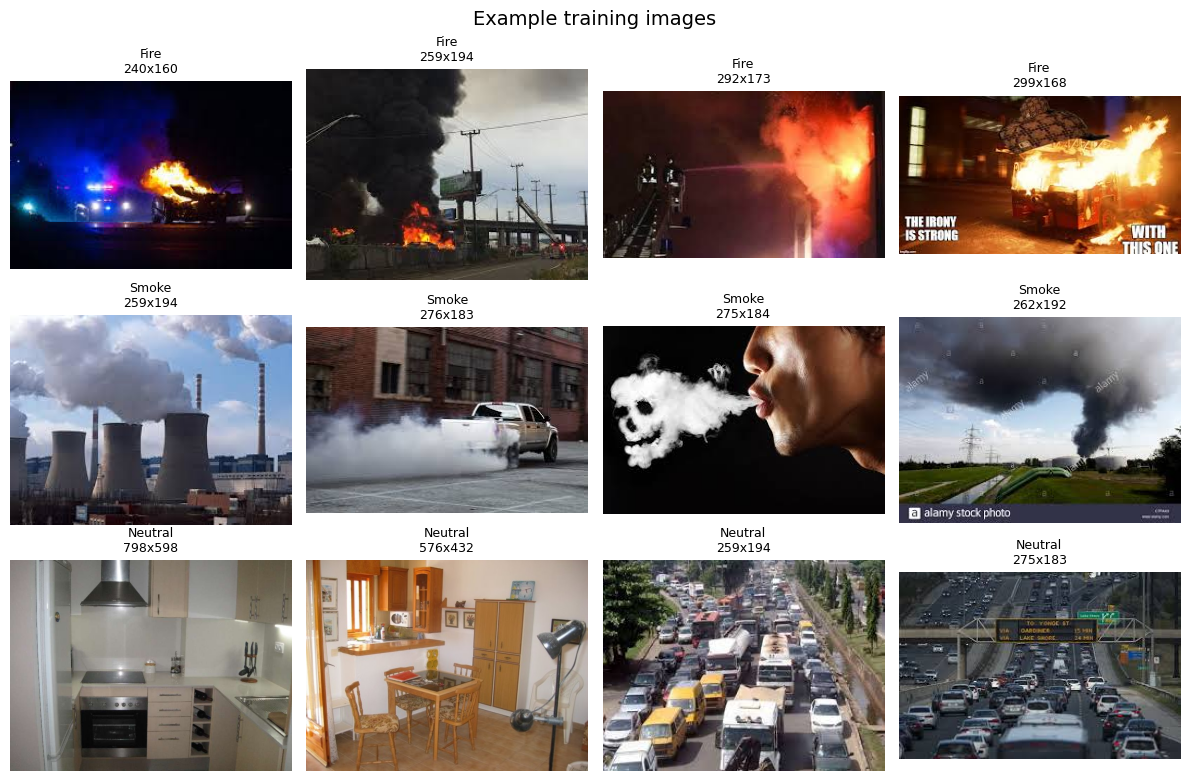

In [5]:
def read_rgb(path):
    bgr = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if bgr is None:
        return None
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

fig, axes = plt.subplots(len(CLASSES), 4, figsize=(12, 8))
for row, label in enumerate(CLASSES):
    paths = inventory[(inventory.split == "Train") & (inventory.label == label)]["path"].head(4)
    for col, path in enumerate(paths):
        ax = axes[row, col]
        image = read_rgb(path)
        ax.imshow(image)
        ax.set_title(f"{label}\n{image.shape[1]}x{image.shape[0]}", fontsize=9)
        ax.axis("off")
fig.suptitle("Example training images", fontsize=14)
fig.tight_layout()
plt.show()


## 3. How the dataset varies

Three kinds of variation matter for this classifier.

**Category balance.** The task is a three-way classification. If one class had far more images, accuracy would be a poor summary. The bar chart checks that.

**Size and resolution.** The files are not one camera setting. Width and height change from image to image, and many files are small. Every feature below is computed after a resize to 224 by 224, which is the input size ResNet50 expects. Direct resize changes the aspect ratio. That is a deliberate trade: every image then occupies the same pixel grid, and black padding does not get counted as part of the scene.

**Appearance.** Flame hue, brightness, and size change inside the Fire class. Smoke changes in density and in how much of the frame it covers. Neutral images differ in background, lighting, and whether any warm colors are present. The resolution scatter and the pixel-count table are the quantitative part of that description. The feature plots later in the notebook show the appearance part.


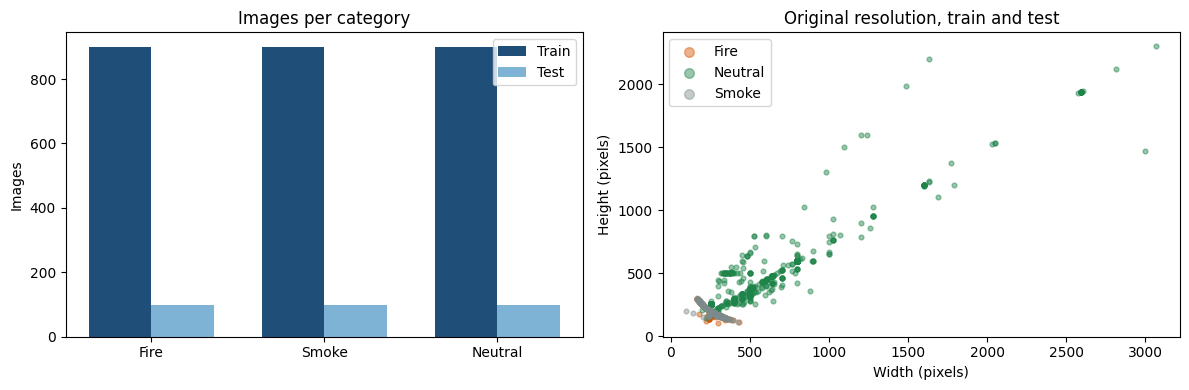

width              height              pixels                   
          min median   max    min median   max    min    median      max
label                                                                   
Fire      168  275.0   429    108  183.0   300  27060   50364.5    50625
Neutral   176  480.0  3072    145  343.5  2304  32120  167000.0  7077888
Smoke      96  275.0   427    118  183.0   307  19488   50325.0    50625

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

count_plot = counts.T  # label x split
x = np.arange(len(CLASSES))
width = 0.36
axes[0].bar(x - width / 2, count_plot["Train"], width, label="Train", color="#1f4e79")
axes[0].bar(x + width / 2, count_plot["Test"], width, label="Test", color="#7fb3d5")
axes[0].set_xticks(x)
axes[0].set_xticklabels(CLASSES)
axes[0].set_ylabel("Images")
axes[0].set_title("Images per category")
axes[0].legend()

for label, group in inventory.groupby("label"):
    axes[1].scatter(
        group["width"],
        group["height"],
        s=12,
        alpha=0.45,
        c=CLASS_COLORS[label],
        label=label,
    )
axes[1].set_xlabel("Width (pixels)")
axes[1].set_ylabel("Height (pixels)")
axes[1].set_title("Original resolution, train and test")
axes[1].legend(markerscale=2)

fig.tight_layout()
plt.show()

size_summary = (
    inventory.groupby("label")[["width", "height", "pixels"]]
    .agg(["min", "median", "max"])
)
size_summary


## 4. Classification problem and the features chosen for it

**Problem.** Given one RGB image, predict one of three labels: Fire, Smoke, or Neutral. About 900 training images and 100 test images are expected in each category. The exact counts are in the table above.

**Why these three features.** The classes overlap in ways that a single descriptor handles badly. Fire is partly a color event (yellow, orange, and red, usually bright). Smoke is partly a texture and contrast event (a soft gray or white region that still lets the background show through). Neutral images can contain sunsets, headlights, or orange objects, so color by itself will make mistakes. The three features below answer three different questions.

**Simple feature: HSV histogram (48 numbers).** Sixteen bins each for hue, saturation, and value, each channel scaled to sum to 1. Hue separates orange flame from green or blue backgrounds. Saturation separates colorful flame from gray smoke. Value separates a bright flame core from a dark frame. A histogram throws away position, which is acceptable for a first feature and matches the proposal. Edges and raw pixels would mostly measure the background, because the flame is often a small part of the frame.

**Hand-designed feature: flame-region geometry (11 numbers).** A fixed color rule marks pixels that look like flame: OpenCV hue at most 25 or at least 160 (red), or hue from 15 to 40 (yellow), with saturation at least 90 and value at least 140 (yellow also requires value at least 160). From that mask the notebook records:

- fire fraction, the share of pixels that pass the rule
- centroid row and column, as a fraction of the frame
- share of those pixels in the top, middle, and bottom third
- bounding-box height and width, as a fraction of the frame, and their ratio
- compactness, `4 * pi * area / perimeter^2` of the mask contours
- edge density, Canny edge pixels inside the mask divided by mask area

This is the custom feature from the proposal: how much flame-colored area there is, where it sits, what shape it has, and whether its boundary is sharp. Smoke and neutral images should score near zero on fire fraction. A sunset can still light the rule up, which is why this feature is paired with the other two rather than used alone.

**Pretrained feature: ResNet50 embedding (2048 numbers).** The network is the ImageNet ResNet50 with its classification layer removed, so each image becomes the 2048-dimensional global-average-pooled vector from the last convolutional stage. Those coordinates were learned on a large set of photographs. They respond to texture, object context, and scene layout that a hue threshold cannot name: a plume against trees, a room interior, a night street. The illustration for this feature is the mean activation of that last stage, resized onto the image, so we can see where the network was responding.

Features for modeling are computed on the training images only. The test folder is counted in the EDA and then left alone.


In [7]:
HSV_BINS = 16
HAND_NAMES = [
    "fire_fraction",
    "centroid_row",
    "centroid_col",
    "mass_top",
    "mass_middle",
    "mass_bottom",
    "bbox_height_frac",
    "bbox_width_frac",
    "aspect",
    "compactness",
    "edge_density",
]

def resize_rgb(image, size=IMAGE_SIZE):
    return cv2.resize(image, (size, size), interpolation=cv2.INTER_AREA)

def hsv_histogram(rgb, bins=HSV_BINS):
    """Simple feature. Per-channel HSV histogram, 16 bins, each channel sums to 1."""
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
    ranges = [(0, 180), (0, 256), (0, 256)]
    parts = []
    for channel, (low, high) in enumerate(ranges):
        hist = cv2.calcHist([hsv], [channel], None, [bins], [low, high]).flatten()
        parts.append(hist / (hist.sum() + 1e-8))
    return np.concatenate(parts).astype(np.float32)

def flame_mask(rgb):
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
    hue, sat, val = cv2.split(hsv)
    red = ((hue <= 25) | (hue >= 160)) & (sat >= 90) & (val >= 140)
    yellow = (hue >= 15) & (hue <= 40) & (sat >= 90) & (val >= 160)
    return (red | yellow).astype(np.uint8)

def flame_features(rgb):
    """Hand-designed feature. Geometry of the flame-colored mask."""
    mask = flame_mask(rgb)
    height, width = mask.shape
    area = float(mask.sum())
    total = float(height * width)
    if area < 1:
        return np.zeros(len(HAND_NAMES), dtype=np.float32), mask

    rows, cols = np.nonzero(mask)
    centroid_row = rows.mean() / height
    centroid_col = cols.mean() / width
    mass_top = float((rows < height / 3).mean())
    mass_middle = float(((rows >= height / 3) & (rows < 2 * height / 3)).mean())
    mass_bottom = float((rows >= 2 * height / 3).mean())
    box_h = (rows.max() - rows.min() + 1) / height
    box_w = (cols.max() - cols.min() + 1) / width
    aspect = box_w / (box_h + 1e-8)

    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    perimeter = sum(cv2.arcLength(contour, True) for contour in contours)
    compactness = (4 * np.pi * area) / (perimeter * perimeter + 1e-8)

    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    edges = cv2.Canny(gray, 80, 160)
    edge_density = float(((edges > 0) & (mask > 0)).sum()) / area

    vector = np.array([
        area / total,
        centroid_row,
        centroid_col,
        mass_top,
        mass_middle,
        mass_bottom,
        box_h,
        box_w,
        aspect,
        compactness,
        edge_density,
    ], dtype=np.float32)
    return vector, mask

def canny_edges(rgb):
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    return cv2.Canny(gray, 80, 160)


## 5. Feature illustrations

One training image from each class, resized to 224 by 224. Columns:

1. The resized image.
2. The HSV histogram (the simple feature). Hue is drawn on 0 to 180 because that is OpenCV's hue range. Saturation and value use 0 to 255.
3. The flame-color mask and the Canny edges that the hand-designed feature is built from.
4. The mean ResNet50 last-stage activation, upsampled and drawn over the image. Bright regions are where the pretrained network responded most, averaged across the 2048 channels. This is an illustration of the learned feature, not the 2048 numbers themselves. The numbers are extracted in the next section.


Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:02<00:00, 50.2MB/s]


ResNet50 ready on cpu


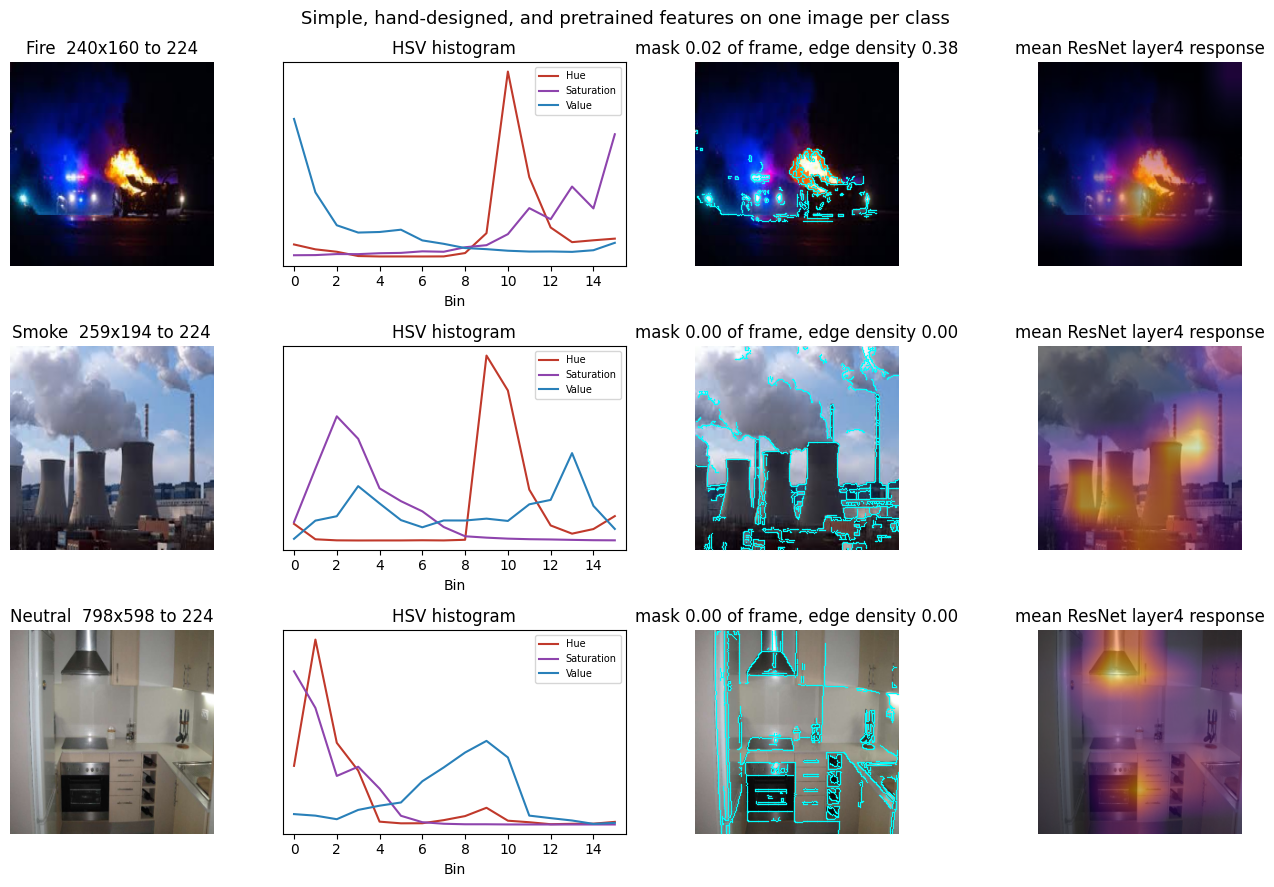

In [8]:
weights = ResNet50_Weights.DEFAULT
resnet = resnet50(weights=weights)
resnet.fc = nn.Identity()
resnet.eval()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
resnet = resnet.to(device)
preprocess = weights.transforms()

# Keep the last convolutional map so the example images can show where the net responded.
_last_map = {}

def _store_layer4(_module, _inputs, output):
    _last_map["map"] = output.detach()

resnet.layer4.register_forward_hook(_store_layer4)
print("ResNet50 ready on", device)

def resnet_one(rgb):
    tensor = preprocess(Image.fromarray(rgb)).unsqueeze(0).to(device)
    with torch.no_grad():
        vector = resnet(tensor)
    activation = _last_map["map"][0].mean(dim=0).cpu().numpy()
    return vector.squeeze(0).cpu().numpy(), activation

def plot_hsv(ax, rgb):
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
    ranges = [(0, 180), (0, 256), (0, 256)]
    colors = ["#c0392b", "#8e44ad", "#2980b9"]
    names = ["Hue", "Saturation", "Value"]
    bins = np.arange(HSV_BINS)
    for channel, ((low, high), color, name) in enumerate(zip(ranges, colors, names)):
        hist = cv2.calcHist([hsv], [channel], None, [HSV_BINS], [low, high]).flatten()
        hist = hist / (hist.sum() + 1e-8)
        ax.plot(bins, hist, color=color, label=name)
    ax.set_xlim(-0.5, HSV_BINS - 0.5)
    ax.set_xlabel("Bin")
    ax.legend(fontsize=7, loc="upper right")
    ax.set_yticks([])

example_paths = []
for label in CLASSES:
    path = inventory[(inventory.split == "Train") & (inventory.label == label)]["path"].iloc[0]
    example_paths.append((label, path))

fig, axes = plt.subplots(len(CLASSES), 4, figsize=(14, 9))
for row, (label, path) in enumerate(example_paths):
    original = read_rgb(path)
    image = resize_rgb(original)
    vector, mask = flame_features(image)
    edges = canny_edges(image)
    embedding, activation = resnet_one(image)
    activation = cv2.resize(activation, (IMAGE_SIZE, IMAGE_SIZE))

    axes[row, 0].imshow(image)
    axes[row, 0].set_title(f"{label}  {original.shape[1]}x{original.shape[0]} to 224")
    axes[row, 0].axis("off")

    plot_hsv(axes[row, 1], image)
    axes[row, 1].set_title("HSV histogram")

    overlay = image.copy()
    overlay[mask > 0] = (0.35 * overlay[mask > 0] + 0.65 * np.array([255, 80, 0])).astype(np.uint8)
    edge_rows, edge_cols = np.nonzero(edges)
    axes[row, 2].imshow(overlay)
    axes[row, 2].scatter(edge_cols, edge_rows, s=1, c="cyan", linewidths=0)
    axes[row, 2].set_title(
        f"mask {vector[0]:.2f} of frame, edge density {vector[-1]:.2f}"
    )
    axes[row, 2].axis("off")

    axes[row, 3].imshow(image)
    axes[row, 3].imshow(activation, cmap="inferno", alpha=0.55)
    axes[row, 3].set_title("mean ResNet layer4 response")
    axes[row, 3].axis("off")

fig.suptitle("Simple, hand-designed, and pretrained features on one image per class", fontsize=13)
fig.tight_layout()
plt.show()


## 6. Extract features for the training set

HSV and the flame geometry are computed on the 224 by 224 image. The ResNet embedding uses the library's own ImageNet preprocessing, which resizes and normalizes the original file, so the learned feature is not tied to our stretch-resize.

`QUICK = True` keeps 40 images per class so the rest of the notebook can be checked in a few minutes. Leave it `False` for the writeup.


In [ ]:
train = inventory[inventory.split == "Train"].copy()
if QUICK:
    parts = []
    for label, frame in train.groupby("label"):
        n = min(SAMPLE_PER_CLASS, len(frame))
        parts.append(frame.sample(n, random_state=RANDOM_STATE))
    train = pd.concat(parts, ignore_index=True)
    print("Quick mode:", train.groupby("label").size().to_dict())
else:
    print("Full training set:", len(train))

paths = train["path"].tolist()
labels = train["label"].tolist()

hsv_rows = []
hand_rows = []
for path in tqdm(paths, desc="HSV and flame features"):
    image = resize_rgb(read_rgb(path))
    hsv_rows.append(hsv_histogram(image))
    hand_vector, _mask = flame_features(image)
    hand_rows.append(hand_vector)

X_hsv = np.vstack(hsv_rows)
X_hand = np.vstack(hand_rows)
print("HSV:", X_hsv.shape, "flame geometry:", X_hand.shape)

def embed_paths(image_paths, batch_size=32):
    vectors = []
    for start in tqdm(range(0, len(image_paths), batch_size), desc="ResNet50"):
        batch_paths = image_paths[start:start + batch_size]
        images = []
        for path in batch_paths:
            with Image.open(path) as im:
                images.append(preprocess(im.convert("RGB")))
        tensors = torch.stack(images).to(device)
        with torch.no_grad():
            batch_vectors = resnet(tensors)
        vectors.append(batch_vectors.cpu().numpy())
    return np.vstack(vectors)

batch_size = 32 if torch.cuda.is_available() else 16
X_resnet = embed_paths(paths, batch_size=batch_size)
y = np.array(labels)
print("ResNet:", X_resnet.shape)


Full training set: 2700


HSV and flame features:   0%|          | 0/2700 [00:00<?, ?it/s]

HSV: (2700, 48) flame geometry: (2700, 11)


ResNet50:   0%|          | 0/169 [00:00<?, ?it/s]

## 7. Variation of the extracted features

The histogram panel is the mean HSV histogram of each class. If the simple feature is doing what we expect, Fire peaks at low hue (red and orange in OpenCV, where 0 is red) with higher saturation, and Smoke puts more mass at low saturation.

The box plots are the hand-designed numbers. Fire fraction should sit higher for Fire than for Smoke or Neutral. The centroid and the third-of-frame masses say whether flame-colored pixels cluster in one part of the picture. Edge density is only meaningful when the mask is non-empty, so a class with almost no flame-colored pixels will pile up at zero.

The bar chart counts how many training images of each class have a flame mask that covers at least 1% of the frame. That is a direct view of how often the color rule fires outside the Fire class.


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharey=True)
channel_names = ["Hue", "Saturation", "Value"]
for channel, ax in enumerate(axes):
    start, stop = channel * HSV_BINS, (channel + 1) * HSV_BINS
    for label in CLASSES:
        mean_hist = X_hsv[y == label, start:stop].mean(axis=0)
        ax.plot(mean_hist, color=CLASS_COLORS[label], label=label)
    ax.set_title(f"Mean {channel_names[channel]} histogram")
    ax.set_xlabel("Bin")
axes[0].set_ylabel("Share of pixels")
axes[0].legend()
fig.tight_layout()
plt.show()

plot_names = ["fire_fraction", "centroid_row", "mass_top", "mass_bottom", "compactness", "edge_density"]
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, name in zip(axes.ravel(), plot_names):
    column = HAND_NAMES.index(name)
    series = [X_hand[y == label, column] for label in CLASSES]
    try:
        box = ax.boxplot(series, tick_labels=CLASSES, patch_artist=True, showfliers=False)
    except TypeError:
        box = ax.boxplot(series, labels=CLASSES, patch_artist=True, showfliers=False)
    for patch, label in zip(box["boxes"], CLASSES):
        patch.set_facecolor(CLASS_COLORS[label])
        patch.set_alpha(0.7)
    ax.set_title(name)
fig.suptitle("Hand-designed flame features by class")
fig.tight_layout()
plt.show()

triggered = [
    float((X_hand[y == label, 0] >= 0.01).mean())
    for label in CLASSES
]
fig, ax = plt.subplots(figsize=(5.5, 3.5))
ax.bar(CLASSES, triggered, color=[CLASS_COLORS[label] for label in CLASSES])
ax.set_ylim(0, 1)
ax.set_ylabel("Share of training images")
ax.set_title("Flame mask covers at least 1% of the frame")
fig.tight_layout()
plt.show()

hand_means = pd.DataFrame(X_hand, columns=HAND_NAMES)
hand_means["label"] = y
hand_means.groupby("label")[HAND_NAMES].mean().reindex(CLASSES).round(3)


## 8. PCA

Each feature family is standardized on its own, then reduced with PCA. Standardizing first keeps a wide-ranging coordinate (edge density, a ResNet unit) from dominating a 0 to 1 coordinate (fire fraction, a histogram bin).

The scatter plots are the first two principal components of each family, colored by class. The curves show how much variance those components keep. A family that separates the classes in this plane is carrying category information in a few directions. Overlap in the plane does not mean the feature is useless: later components, or a nonlinear view such as t-SNE, can still separate the classes.

For the joint view, each family is reduced to 10 principal components and those scores are concatenated. Reducing each family before joining them stops the 2048 ResNet coordinates from outvoting the 48 histogram bins and the 11 flame measurements.


In [ ]:
def scale(matrix):
    return StandardScaler().fit_transform(matrix)

def scatter_by_class(ax, coords, title):
    for label in CLASSES:
        points = coords[y == label]
        ax.scatter(
            points[:, 0], points[:, 1],
            s=10, alpha=0.45, c=CLASS_COLORS[label], label=label,
        )
    ax.set_title(title)
    ax.set_xlabel("Component 1")
    ax.set_ylabel("Component 2")

families = {
    "HSV histogram": scale(X_hsv),
    "Flame geometry": scale(X_hand),
    "ResNet50": scale(X_resnet),
}

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
pca_scores = {}
for ax, (name, matrix) in zip(axes, families.items()):
    pca = PCA(n_components=2, random_state=RANDOM_STATE)
    scores = pca.fit_transform(matrix)
    pca_scores[name] = scores
    scatter_by_class(ax, scores, name)
    kept = 100 * pca.explained_variance_ratio_.sum()
    ax.set_xlabel(f"Component 1+2 keep {kept:.1f}%")
axes[0].legend(markerscale=2, loc="best")
fig.suptitle("PCA of each feature family")
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 3.5))
for name, matrix in families.items():
    n_components = min(20, matrix.shape[1])
    pca = PCA(n_components=n_components, random_state=RANDOM_STATE).fit(matrix)
    ax.plot(np.arange(1, n_components + 1), np.cumsum(pca.explained_variance_ratio_), label=name)
ax.set_xlabel("Number of components")
ax.set_ylabel("Cumulative share of variance")
ax.set_ylim(0, 1.02)
ax.set_title("How much variance PCA keeps")
ax.legend()
fig.tight_layout()
plt.show()

joint_blocks = []
for name, matrix in families.items():
    n_components = min(10, matrix.shape[1])
    joint_blocks.append(PCA(n_components=n_components, random_state=RANDOM_STATE).fit_transform(matrix))
X_joint = np.hstack(joint_blocks)
print("Joint PCA matrix:", X_joint.shape, "(10 components from each family)")

pca_joint = PCA(n_components=2, random_state=RANDOM_STATE)
joint_2d = pca_joint.fit_transform(X_joint)
fig, ax = plt.subplots(figsize=(6, 4.5))
scatter_by_class(ax, joint_2d, "PCA of the joint 30-dimensional feature")
kept = 100 * pca_joint.explained_variance_ratio_.sum()
ax.set_xlabel(f"Component 1+2 keep {kept:.1f}% of the joint 30")
ax.legend(markerscale=2)
fig.tight_layout()
plt.show()


## 9. t-SNE

t-SNE is a two-dimensional view that tries to keep nearby points nearby. It is a picture of the feature space, not a classifier, and the axes have no unit. Perplexity is 30 and the random seed is fixed so the picture is repeatable. The input is the same 30-dimensional joint feature used above (10 PCA components from each family), which is a better t-SNE input than the raw 2048-dimensional embedding.

A second t-SNE uses only the ResNet block (its first 10 PCA components). Comparing the two pictures shows how much of the class structure is already present in the pretrained embedding, and how much the color histogram and the flame geometry add when they are included.


In [ ]:
def run_tsne(matrix):
    perplexity = min(30, max(5, (len(matrix) - 1) // 3))
    return TSNE(
        n_components=2,
        perplexity=perplexity,
        init="pca",
        learning_rate="auto",
        random_state=RANDOM_STATE,
    ).fit_transform(matrix)

joint_tsne = run_tsne(X_joint)
resnet_tsne = run_tsne(X_joint[:, 20:30])  # last block is the 10 ResNet components

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
scatter_by_class(axes[0], joint_tsne, "t-SNE of HSV + flame geometry + ResNet")
scatter_by_class(axes[1], resnet_tsne, "t-SNE of ResNet PCA components only")
axes[0].legend(markerscale=2)
fig.tight_layout()
plt.show()


## 10. Reading the methods and the pictures

**What was measured.** The HSV histogram records the color mix and ignores location. The flame feature records only pixels that pass a fixed red/yellow rule, then summarizes how many there are, where they sit, how compact they are, and how sharp their edges are. ResNet50 records a general-purpose photograph embedding from a network trained on ImageNet, with no fire labels involved in that pretraining.

**What the class means should show.** Fire should have the highest mean fire fraction, and it should more often cross the 1% mask threshold. Smoke should put more of its saturation histogram in the low-saturation bins and should rarely produce a large flame mask. Neutral should look more like Smoke than like Fire on the flame features, with a long tail wherever an orange object or a warm light passes the color rule. If the table of class means does not show that ordering, the hue thresholds are too loose or too tight for this collection and should be revisited before they are used in a classifier.

**What the embeddings add.** PCA of the histogram and of the flame geometry will leave a lot of overlap, because many Fire images are mostly background and many Neutral images contain warm colors. The ResNet plane and the ResNet t-SNE should form tighter groups if scene texture and context differ across the three folders. The joint t-SNE is the one to use when writing about the combined feature. Clusters there are neighborhoods in the feature space. They are not a measured accuracy, and a point that lands in the wrong group is a useful error case for the later logistic regression and SVM, not a failure of the visualization.

**What this does not claim.** These plots do not pick the classifier, the regularization, or the decision threshold. Test images were not embedded, so the pictures are a description of the training collection. Stage 2 intensity labels are not in this dataset.


In [ ]:
feature_path = OUTPUT_DIR / "stage1_train_features.npz"
np.savez_compressed(
    feature_path,
    paths=np.array(paths),
    labels=y,
    X_hsv=X_hsv,
    X_hand=X_hand,
    hand_names=np.array(HAND_NAMES),
    X_resnet=X_resnet,
    X_joint_pca10=X_joint,
)
print("Saved", feature_path)
print("HSV", X_hsv.shape, "| flame", X_hand.shape, "| ResNet", X_resnet.shape)
